In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

inspections = pd.read_csv("data/raw/Food_Inspections_20261012.csv")
licenses = pd.read_csv("data/raw/Business_Licenses_20261105.csv", low_memory=False)
cca = pd.read_csv("data/raw/CommunityDataSnapshots_Historical_455993172616713182.csv")
buildings = pd.read_csv("data/raw/Building_Footprints_20261105.csv", low_memory=False)

In [ ]:
inspections = inspections[[
    "Inspection ID", "DBA Name", "License #", "Facility Type",
    "Address", "Inspection Date", "Results", "Violations"
]].copy()

licenses = licenses[[
    "LICENSE NUMBER", "COMMUNITY AREA"
]].copy()

cca = cca[[
    "GEOID", "GEOG", "TOT_POP", "MEDINC"
]].copy()

buildings = buildings[[
    "BLDG_ID", "F_ADD1", "T_ADD1", "PRE_DIR1",
    "ST_NAME1", "ST_TYPE1", "SUF_DIR1", "YEAR_BUILT"
]].copy()

inspections["Inspection Date"] = pd.to_datetime(
    inspections["Inspection Date"]
)

inspections = inspections[
    inspections["Facility Type"] == "Restaurant"
].copy()

inspections = inspections.drop_duplicates()

inspections["License #"] = pd.to_numeric(inspections["License #"])
licenses["LICENSE NUMBER"] = pd.to_numeric(licenses["LICENSE NUMBER"])
licenses["COMMUNITY AREA"] = pd.to_numeric(licenses["COMMUNITY AREA"])
cca["GEOID"] = pd.to_numeric(cca["GEOID"])
cca["MEDINC"] = pd.to_numeric(cca["MEDINC"])

licenses = licenses.dropna().drop_duplicates()
licenses = licenses[licenses["LICENSE NUMBER"] > 0]

licenses = licenses[
    ~licenses["LICENSE NUMBER"].duplicated(keep=False)
]

cca = cca.dropna(subset=["GEOID"])

combined = inspections.merge(
    licenses,
    left_on="License #",
    right_on="LICENSE NUMBER",
    how="inner",
    validate="many_to_one"
)

combined = combined.merge(
    cca,
    left_on="COMMUNITY AREA",
    right_on="GEOID",
    how="inner",
    validate="many_to_one"
)

for col in ["F_ADD1", "T_ADD1", "YEAR_BUILT"]:
    buildings[col] = pd.to_numeric(
        buildings[col]
        .astype("string")
        .str.replace(",", "", regex=False)
    )

buildings = buildings[
    buildings["YEAR_BUILT"].between(1, 2026)
    & buildings["F_ADD1"].notna()
    & (buildings["F_ADD1"] == buildings["T_ADD1"])
].copy()

buildings["Address_Match"] = (
    buildings["F_ADD1"].astype("Int64").astype("string")
    + " " + buildings["PRE_DIR1"].fillna("")
    + " " + buildings["ST_NAME1"].fillna("")
    + " " + buildings["ST_TYPE1"].fillna("")
    + " " + buildings["SUF_DIR1"].fillna("")
).str.upper().str.replace(r"\s+", " ", regex=True).str.strip()

combined["Address_Match"] = (
    combined["Address"]
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

building_lookup = buildings[[
    "Address_Match", "BLDG_ID", "YEAR_BUILT"
]].drop_duplicates()

building_lookup = building_lookup[
    ~building_lookup["Address_Match"].duplicated(keep=False)
]

combined = combined.merge(
    building_lookup,
    on="Address_Match",
    how="left",
    validate="many_to_one"
)

future_building = (
    combined["YEAR_BUILT"] > combined["Inspection Date"].dt.year
).fillna(False)

combined.loc[
    future_building, ["BLDG_ID", "YEAR_BUILT"]
] = pd.NA

combined["Building_Age"] = (
    combined["Inspection Date"].dt.year - combined["YEAR_BUILT"]
)

results = combined[
    combined["Results"].isin(["Pass", "Fail"])
].copy()

summary = (
    results.groupby(["GEOG", "MEDINC", "Results"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Pass", "Fail"], fill_value=0)
    .reset_index()
)

summary["Total"] = summary["Pass"] + summary["Fail"]
summary["Fail_Percent"] = summary["Fail"] / summary["Total"] * 100
summary["Pass_Fail_Gap"] = summary["Pass"] - summary["Fail"]

summary = summary.sort_values("Fail_Percent", ascending=False)

print("Restaurant inspections before joins:", len(inspections))
print("Inspections matched to licenses and CMAP:", len(combined))
print(
    "Inspections with building age:",
    combined["Building_Age"].notna().sum()
)
print(
    "Inspection date range:",
    combined["Inspection Date"].min(),
    "to",
    combined["Inspection Date"].max()
)

display(combined[[
    "DBA Name", "Address", "Inspection Date", "GEOG",
    "Results", "YEAR_BUILT", "Building_Age"
]].head(10))

display(summary)


Restaurant inspections before joins: 215026
Inspections matched to licenses and CMAP: 211493
Inspections with building age: 58084
Inspection date range: 2010-01-04 00:00:00 to 2026-10-09 00:00:00


,DBA Name,Address,Inspection Date,GEOG,Results,YEAR_BUILT,Building_Age
0,SIMPLY SOUPS SALADS & SANDWICHES,635 E 47TH ST,2026-10-09,Grand Boulevard,Pass,2008,18
1,AGLAIA COFFEE AND TEA COMPANY,925 W CHICAGO AVE,2026-10-09,West Town,Fail,1904,122
2,SIP & SAVOR COFFEE HOUSE,528 E 43RD ST,2026-10-09,Grand Boulevard,Fail,<NA>,<NA>
3,FUERZA VITAL,8542 S PULASKI RD,2026-10-09,Ashburn,Pass,<NA>,<NA>
4,SHARKS ON DIVISION CORPORATION,5751 W DIVISION ST,2026-10-08,Austin,Fail,<NA>,<NA>
5,LA QUINTA INN AND SUITES CHICAGO DOWNTOWN,1 S FRANKLIN ST,2026-10-08,The Loop,Pass,1958,68
6,CILANTRO TACO GRILL - LOOP,180 N WELLS ST,2026-10-08,The Loop,Pass,<NA>,<NA>
7,LA BOMBA FOOD,3221 W ARMITAGE AVE,2026-10-08,Logan Square,Fail,<NA>,<NA>
8,THALI CORNER,2350 W DEVON AVE,2026-10-08,West Ridge,Out of Business,<NA>,<NA>
9,ADORO FUSION KITCHEN + BAR,2509 W NORTH AVE,2026-10-08,West Town,Fail,<NA>,<NA>


Results,GEOG,MEDINC,Pass,Fail,Total,Fail_Percent,Pass_Fail_Gap
67,Washington Park,35737.179487,188,125,313,39.936102,63
57,Riverdale,17638.888889,17,10,27,37.037037,7
70,West Garfield Park,38641.732283,330,175,505,34.653465,155
18,East Garfield Park,37170.329670,246,126,372,33.870968,120
28,Greater Grand Crossing,37961.582569,866,442,1308,33.792049,424
...,...,...,...,...,...,...,...
3,Ashburn,82235.360360,860,202,1062,19.020716,658
15,Clearing,78436.888454,580,116,696,16.666667,464
26,Garfield Ridge,96218.190386,1646,328,1974,16.616008,1318
53,O'Hare,83115.610712,2597,509,3106,16.387637,2088


In [ ]:
businesses = pd.read_csv("data/raw/Business_Licenses_20261105.csv", low_memory=False)

businesses = businesses[
    (businesses["LICENSE DESCRIPTION"] == "Retail Food Establishment")
    & (businesses["CITY"] == "CHICAGO")
].copy()

businesses["COMMUNITY AREA"] = pd.to_numeric(
    businesses["COMMUNITY AREA"]
)

locations = businesses.dropna(
    subset=["ACCOUNT NUMBER", "SITE NUMBER", "COMMUNITY AREA"]
).drop_duplicates(
    subset=["ACCOUNT NUMBER", "SITE NUMBER"]
)

area_counts = (
    locations.groupby("COMMUNITY AREA")
    .size()
    .reset_index(name="Food_Establishment_Count")
)

area_counts = area_counts.merge(
    cca[["GEOID", "GEOG", "MEDINC"]],
    left_on="COMMUNITY AREA",
    right_on="GEOID",
    how="inner",
    validate="one_to_one"
)

area_counts = area_counts.sort_values(
    "Food_Establishment_Count",
    ascending=False
)

display(area_counts[[
    "GEOG", "Food_Establishment_Count", "MEDINC"
]])

,GEOG,Food_Establishment_Count,MEDINC
7,Near North Side,2821,124208.228504
31,The Loop,2789,119470.667566
27,Near West Side,2083,111332.417582
5,Lake View,1981,105498.972954
23,West Town,1832,141208.345621
...,...,...,...
38,Kenwood,80,64745.870394
49,Pullman,74,62475.369458
53,Riverdale,24,17638.888889
46,Burnside,7,46691.176471


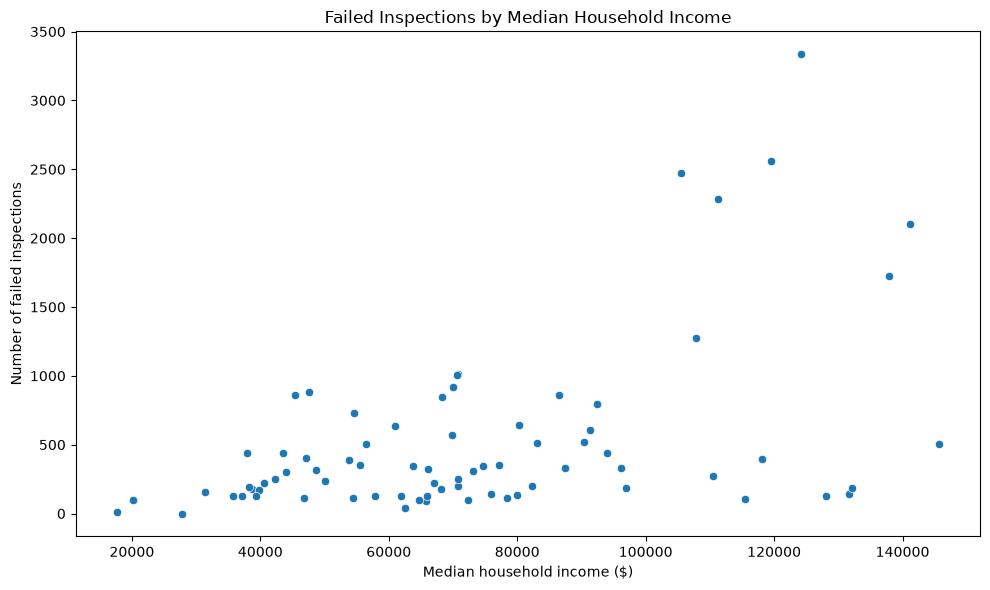

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=summary,
    x="MEDINC",
    y="Fail"
)

plt.title("Failed Inspections by Median Household Income")
plt.xlabel("Median household income ($)")
plt.ylabel("Number of failed inspections")
plt.tight_layout()
plt.savefig("visuals/failed_income_scatterplot.png", dpi=300, bbox_inches="tight")
plt.show()

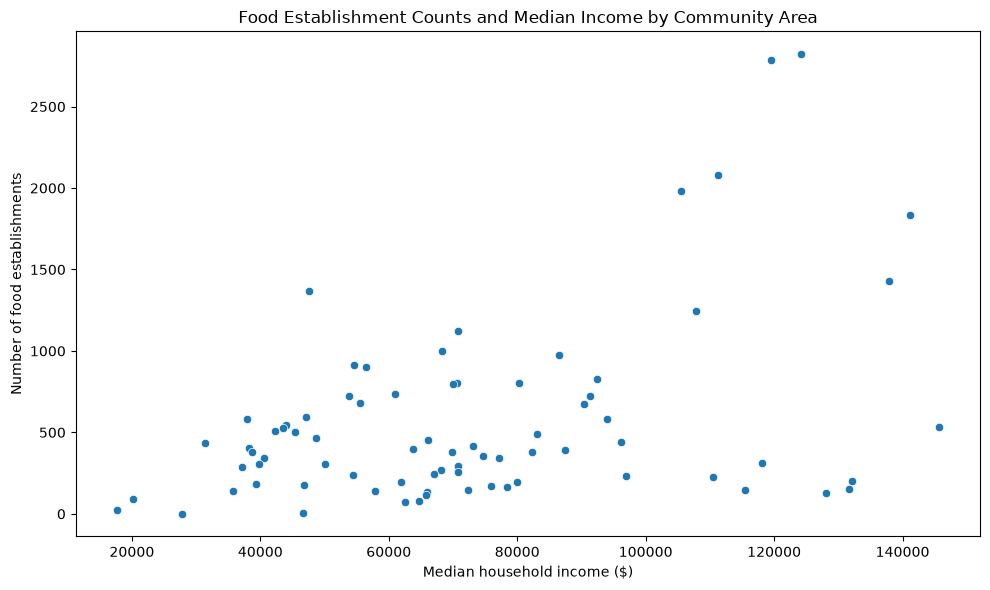

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=area_counts,
    x="MEDINC",
    y="Food_Establishment_Count"
)

plt.title("Food Establishment Counts and Median Income by Community Area")
plt.xlabel("Median household income ($)")
plt.ylabel("Number of food establishments")
plt.tight_layout()
plt.savefig("visuals/food_count_scatterplot.png", dpi=300, bbox_inches="tight")
plt.show()

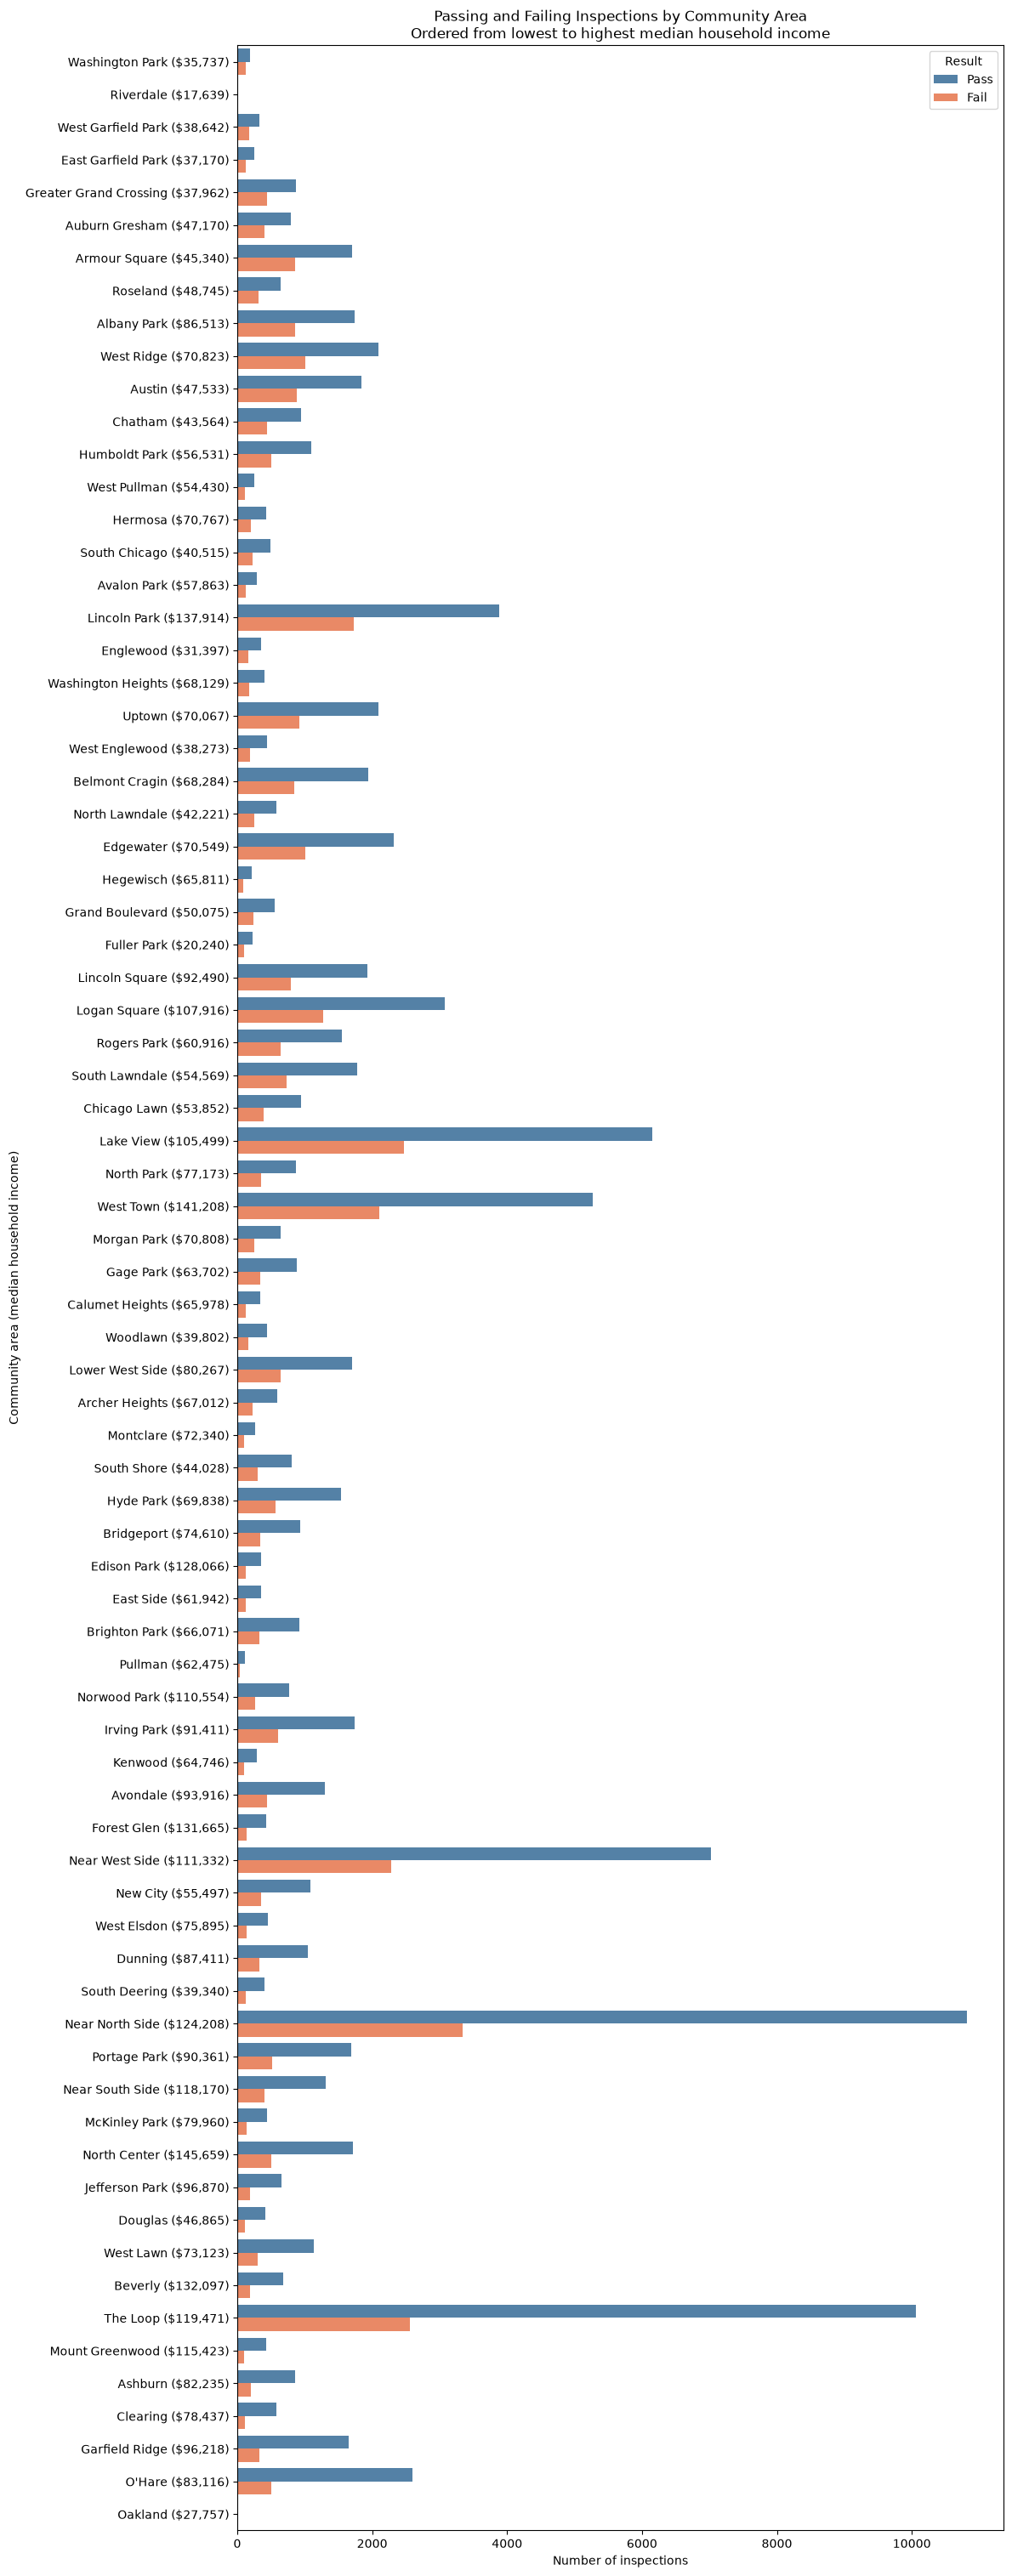

In [14]:
summary["Area_Income"] = (
    summary["GEOG"]
    + " ($"
    + summary["MEDINC"].map("{:,.0f}".format)
    + ")"
)

graph_data = summary.melt(
    id_vars=["Area_Income"],
    value_vars=["Pass", "Fail"],
    var_name="Result",
    value_name="Count"
)

plt.figure(figsize=(12, max(6, len(summary) * 0.4)))

sns.barplot(
    data=graph_data,
    x="Count",
    y="Area_Income",
    hue="Result",
    order=summary["Area_Income"],
    palette={"Pass": "steelblue", "Fail": "coral"}
)

plt.title("Passing and Failing Inspections by Community Area\n"
          "Ordered from lowest to highest median household income")
plt.xlabel("Number of inspections")
plt.ylabel("Community area (median household income)")
plt.tight_layout()
plt.savefig("visuals/passing_fail_bargraph.png", dpi=300, bbox_inches="tight")
plt.show()

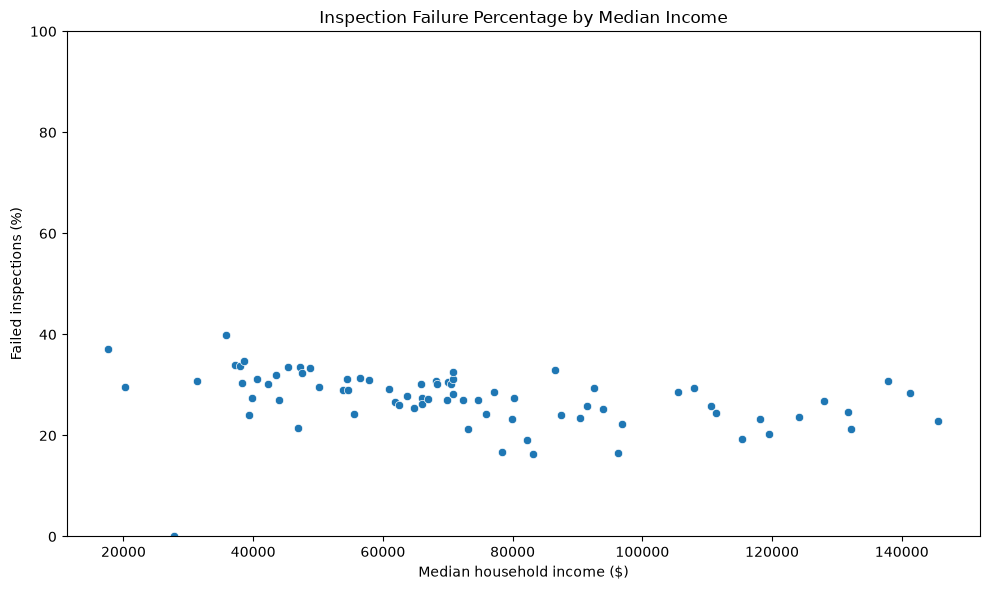

In [15]:
summary = summary.sort_values("MEDINC", ascending=True)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=summary,
    x="MEDINC",
    y="Fail_Percent"
)

plt.title("Inspection Failure Percentage by Median Income")
plt.xlabel("Median household income ($)")
plt.ylabel("Failed inspections (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("visuals/fail_percent_income_scatterplot.png", dpi=300, bbox_inches="tight")
plt.show()

,Inspection ID,DBA Name,License #,Facility Type,Address,Inspection Date,Results,Violations,LICENSE NUMBER,COMMUNITY AREA,GEOID,GEOG,TOT_POP,MEDINC,Address_Match,BLDG_ID,YEAR_BUILT,Building_Age,Failed
0,2644038,SIMPLY SOUPS SALADS & SANDWICHES,2222369.0,Restaurant,635 E 47TH ST,2026-10-09,Pass,"55. PHYSICAL FACILITIES INSTALLED, MAINTAINED ...",2222369.0,38.0,38,Grand Boulevard,25181.000000,50075.107296,635 E 47TH ST,"885,873",2008,18,False
1,2644032,AGLAIA COFFEE AND TEA COMPANY,2749668.0,Restaurant,925 W CHICAGO AVE,2026-10-09,Fail,2. CITY OF CHICAGO FOOD SERVICE SANITATION CER...,2749668.0,24.0,24,West Town,88164.000000,141208.345621,925 W CHICAGO AVE,"339,059",1904,122,True
5,2643999,LA QUINTA INN AND SUITES CHICAGO DOWNTOWN,3100728.0,Restaurant,1 S FRANKLIN ST,2026-10-08,Pass,36. THERMOMETERS PROVIDED & ACCURATE - Comment...,3100728.0,32.0,32,The Loop,42550.000000,119470.667566,1 S FRANKLIN ST,"357,008",1958,68,False
12,2644000,LA QUINTA INN AND SUITES CHICAGO DOWNTOWN,3100729.0,Restaurant,1 S FRANKLIN ST,2026-10-08,Pass,NaN,3100729.0,32.0,32,The Loop,42550.000000,119470.667566,1 S FRANKLIN ST,"357,008",1958,68,False
15,2643928,ROTI,3104210.0,Restaurant,1012 W RANDOLPH ST,2026-10-07,Pass,45. SINGLE-USE/SINGLE-SERVICE ARTICLES: PROPER...,3104210.0,28.0,28,Near West Side,68165.000000,111332.417582,1012 W RANDOLPH ST,"879,755",1924,102,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211463,60243,ANGELO'S STUFFED PIZZA CORP,1045634.0,Restaurant,4850 S PULASKI RD,2010-01-05,Pass,31. CLEAN MULTI-USE UTENSILS AND SINGLE SERVIC...,1045634.0,57.0,57,Archer Heights,13414.000000,67012.195122,4850 S PULASKI RD,"454,740",1920,90,False
211466,78239,Yahs Cuisine,2004254.0,Restaurant,2347 E 75TH ST,2010-01-05,Fail,"9. WATER SOURCE: SAFE, HOT & COLD UNDER CITY P...",2004254.0,43.0,43,South Shore,53588.000000,44027.916251,2347 E 75TH ST,"593,576",1955,55,True
211476,67758,SU TAQUERIA EL GALLO BRAVO #4,1766968.0,Restaurant,5650 W GRAND AVE,2010-01-05,Fail,19. OUTSIDE GARBAGE WASTE GREASE AND STORAGE A...,1766968.0,19.0,19,Belmont Cragin,72088.000000,68284.213224,5650 W GRAND AVE,"282,067",1905,105,True
211481,118298,FERRO'S,12342.0,Restaurant,200 W 31ST ST,2010-01-05,Pass,"30. FOOD IN ORIGINAL CONTAINER, PROPERLY LABEL...",12342.0,34.0,34,Armour Square,13884.516393,45340.337979,200 W 31ST ST,"406,783",1989,21,False


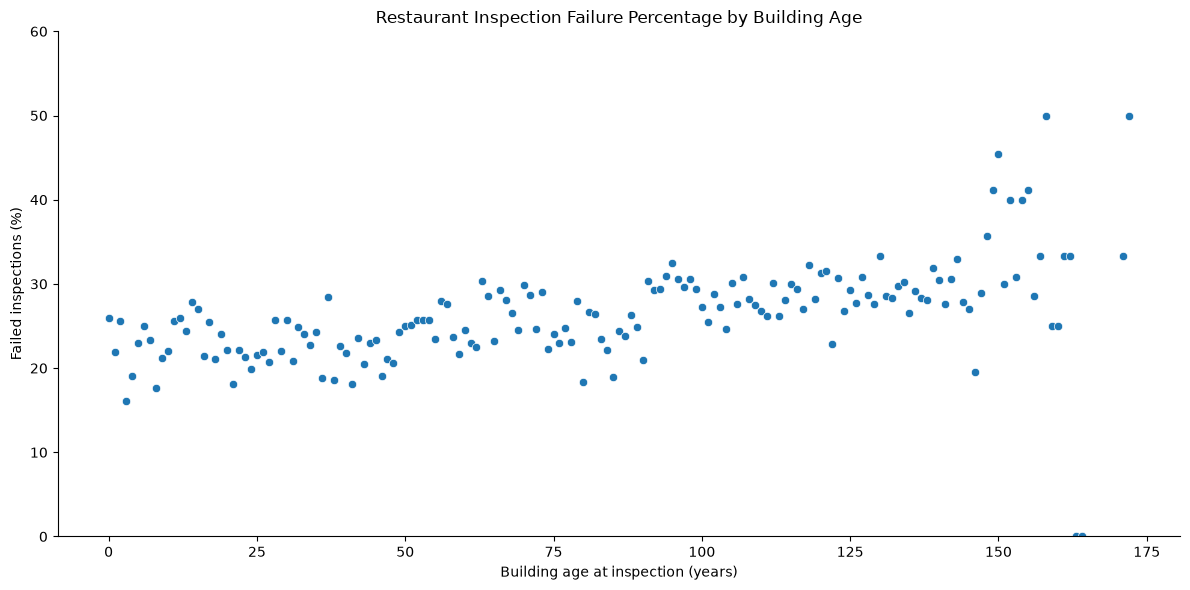

In [17]:
building_results = combined[
    combined["Building_Age"].notna()
    & combined["Results"].isin(["Pass", "Fail"])
].copy()

building_results["Failed"] = (
    building_results["Results"] == "Fail"
)


age_summary = (
    building_results.groupby("Building_Age")
    .agg(
        Total_Inspections=("Failed", "size"),
        Fail_Percent=("Failed", "mean")
    )
    .reset_index()
)
display(building_results)
age_summary["Fail_Percent"] *= 100

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=age_summary,
    x="Building_Age",
    y="Fail_Percent",
)

plt.title("Restaurant Inspection Failure Percentage by Building Age")
plt.xlabel("Building age at inspection (years)")
plt.ylabel("Failed inspections (%)")
plt.ylim(0, 60)
sns.despine()
plt.tight_layout()
plt.savefig("images/failure_percentage_by_building_age.png",dpi=300,bbox_inches="tight")
plt.show()